## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Shravya Etta

**Date:** 10/13/2026

**QUESTION 1**

In [1]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

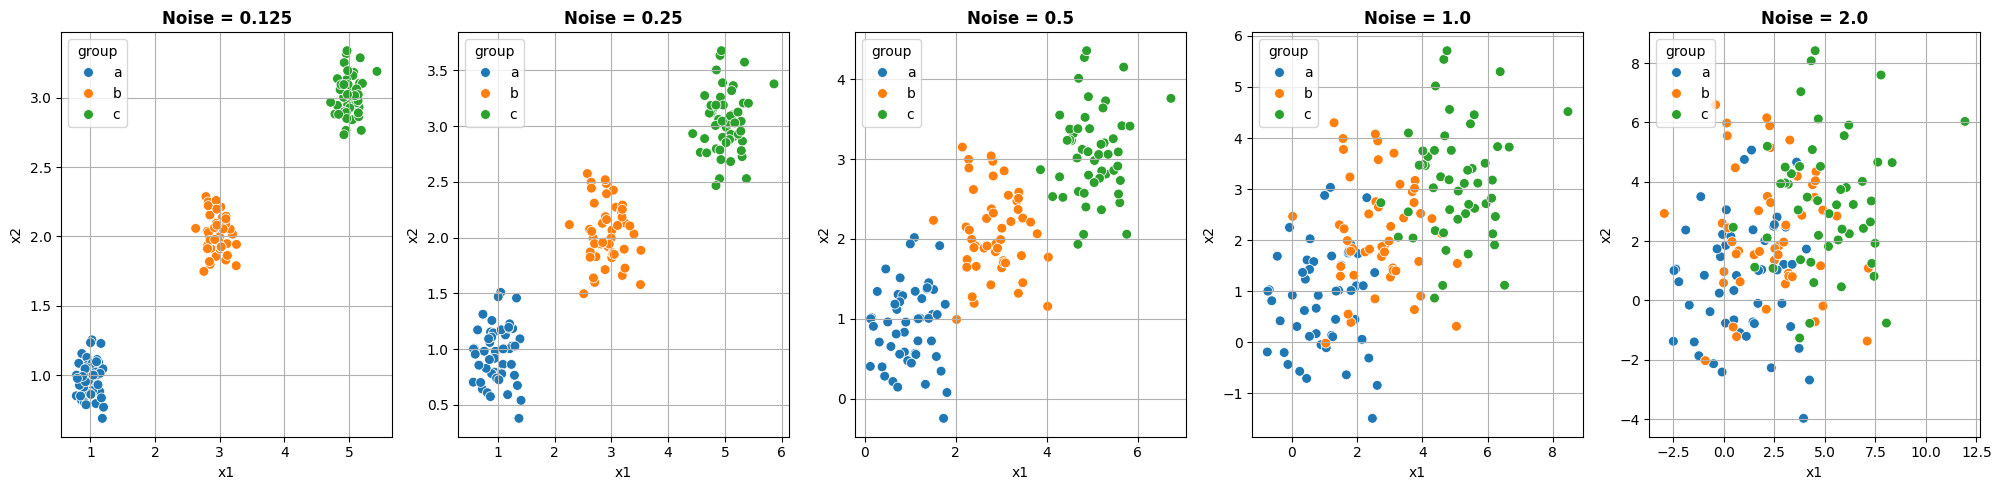

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

datasets = [
    ("Noise = 0.125", df0_125),
    ("Noise = 0.25", df0_25),
    ("Noise = 0.5", df0_5),
    ("Noise = 1.0", df1_0),
    ("Noise = 2.0", df2_0),
]

fig, axes = plt.subplots(1, 5, figsize=(20, 5), sharex=False, sharey=False)

for ax, (title, df) in zip(axes, datasets):
    sns.scatterplot(data=df, x='x1', y='x2', hue='group', s=50, ax=ax)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.grid(True)

plt.tight_layout()
plt.show()

As noise increases from 0.125 to 2.0, there is increasingly less distinctness between clusters. The clusters are mostly distinct with noise levels of 0.125-0.25, still partially separated with a noise of 0.5, and interdispersed with noise levels of 1 and greater.

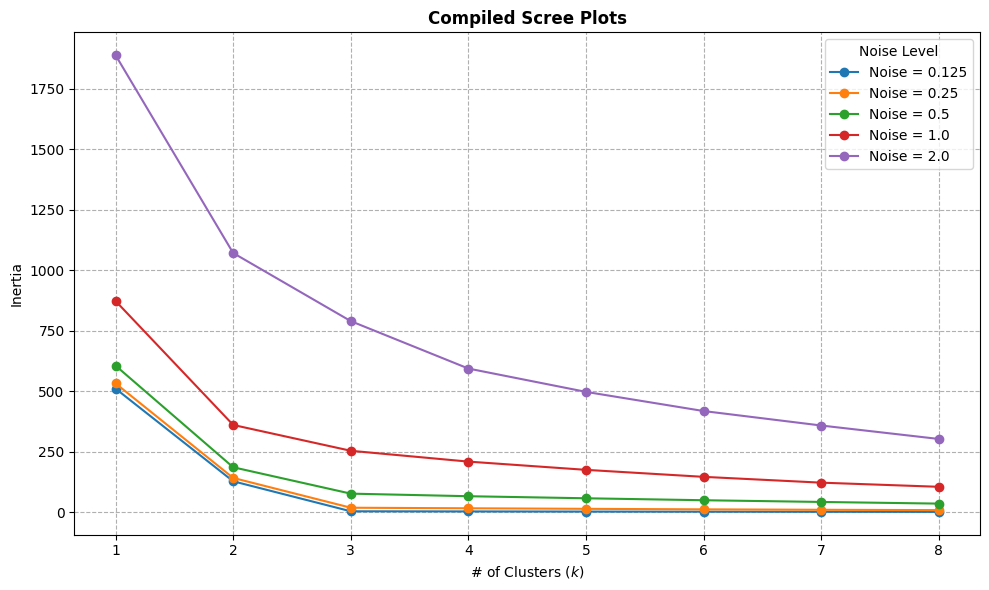

In [16]:
inertia_results = {}

for label, df in datasets:
    X = df[['x1', 'x2']]
    inertias = []
    for k in range(1, 9):
        km = KMeans(n_clusters=k, random_state=100, n_init=10)
        km.fit(X)
        inertias.append(km.inertia_)
    inertia_results[label] = inertias

plt.figure(figsize=(10, 6))
for label, inertias in inertia_results.items():
    plt.plot(list(range(1, 9)), inertias, marker='o', label=label)

plt.title("Compiled Scree Plots", fontweight='bold')
plt.xlabel("# of Clusters ($k$)")
plt.ylabel("Inertia")
plt.xticks(list(range(1, 9)))
plt.grid(True, linestyle='--')
plt.legend(title="Noise Level")
plt.tight_layout()
plt.show()

At lower noise levels of 0.125-0.5, inertia drops significantly from cluster to cluster, almost leveling off to 0 by k = 3. At higher noise levels, the drop in intertia is more gradual. Hence, for noise levels less than 0.5, identifying the true value of k = 3 is more straightforward because of the presence of a distinct bend in the curve, while choosing a k value is harder and more unreliable with higher noise levels.

The elbow represents the point of peak efficiency in terms of variance. Before the elbow, increasing the number of clusters results in more centroids to separate clusters. At the elbow, each cluster has it's own centroid. After the elbow, adding more clusters takes away from the already formed clusters. When noise is low, the boundary between capturing real structure and splitting existing clusters is more clear.

**QUESTION 2**

In [18]:
df = pd.read_csv('SIPRI Military Expenditure Database.csv')

df.columns = df.columns.str.strip()

df_2020 = df[df['Year'] == 2020].dropna().copy()
print(f"# of countries: {len(df_2020)}")

# of countries: 148


In [20]:
df_2020.head() # checking to see if more cleaning is needed

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


Based on the output above, I concluded that no further cleaning is required.

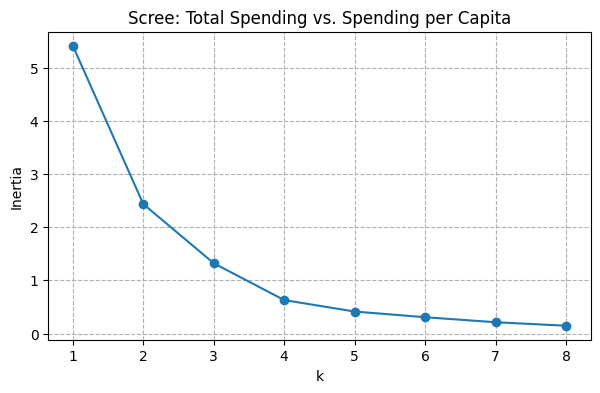

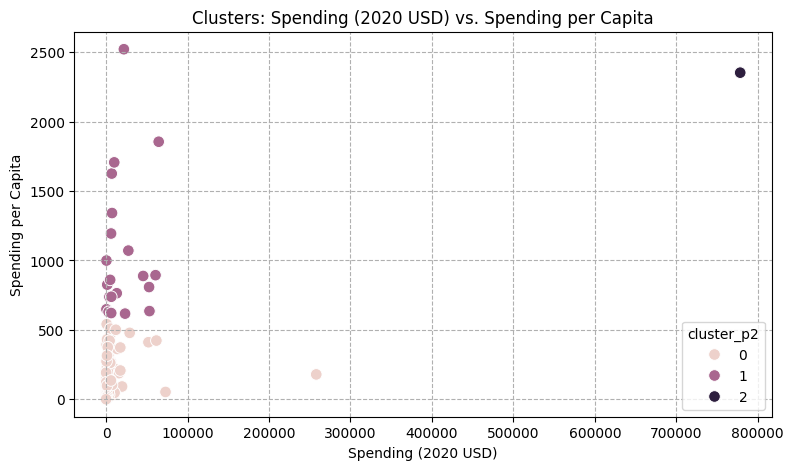

cluster_p2                             0             1              2
Spending (2020 USD) count     126.000000     21.000000       1.000000
                    mean     5943.346303  19975.991473  778397.200000
                    std     24858.961064  21749.736747            NaN
                    min         8.622460    405.790494  778397.200000
                    25%       162.761743   4980.428135  778397.200000
                    50%       580.758315   7269.880030  778397.200000
                    75%      3225.333414  27300.894701  778397.200000
                    max    257973.429834  64558.400000  778397.200000
Spending per Capita count     126.000000     21.000000       1.000000
                    mean      122.034996   1046.433509    2351.631858
                    std       140.041183    501.631845            NaN
                    min         0.580129    616.854430    2351.631858
                    25%        18.505805    737.690186    2351.631858
                    

In [27]:
from sklearn.preprocessing import MinMaxScaler

features_p2 = ['Spending (2020 USD)', 'Spending per Capita']

scaler_p2 = MinMaxScaler()
X_p2norm = scaler_p2.fit_transform(df_2020[features_p2])

# scree plot
inertias_p2 = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_p2_norm).inertia_ for k in range(1, 9)]

plt.figure(figsize=(7, 4))
plt.plot(range(1, 9), inertias_p2, marker='o')
plt.title("Scree: Total Spending vs. Spending per Capita")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.grid(True, linestyle='--')
plt.show()

k_optp2 = 3
kmeans_p2 = KMeans(n_clusters=k_optp2, random_state=42, n_init=10)
df_2020['cluster_p2'] = kmeans_p2.fit_predict(X_p2norm)

# scatter plot
plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df_2020,
    x='Spending (2020 USD)',
    y='Spending per Capita',
    hue='cluster_p2',
    s=70
)
plt.title("Clusters: Spending (2020 USD) vs. Spending per Capita")
plt.grid(True, linestyle='--')
plt.show()

# Conditional Describe Table
print(df_2020.groupby('cluster_p2')[features_p2].describe().T)

The United States is an outlier in total expenditure, with ~$778 billion in 2020. Cluster patterns:

*   Cluster 0: Lower overall spending and low-to-moderate per capita spending (which is likely the case for most countries).
*   Cluster 1: Higher per capita values that indicate either wealthy, smaller nations or highly militarized ones with smaller populations.
*   Cluster 2: The United States comprises the majority of absolute spending dimension, as indicated by the normalized value = 1.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]